# 02. Phân tích câu hỏi Non-ml — Câu hỏi 1 (D1 + D3)

> **Người vừa ngủ ít vừa có BMI cao có tỷ lệ thuộc nhóm nguy cơ cao khác thế nào so với người chỉ có một hoặc không có hai đặc điểm này?**

Phân tích theo đề xuất trong [non_ml_question.md](../non_ml_question.md), dùng CSV cục bộ gồm **15.000 hồ sơ tổng hợp**. `High` là nhãn `diabetes_risk` do cơ chế mô phỏng tạo ra; tỷ lệ nhãn này không phải xác suất mắc bệnh hay tỷ lệ bệnh trong cộng đồng. Nguồn và cơ chế sinh dữ liệu đã được trình bày trong [01_collection_exploration.ipynb](01_collection_exploration.ipynb).

Notebook thực hiện **D1: tạo và ghép bảng BMI tham chiếu theo tuổi–giới**, **D3: tạo biến độ lệch BMI và bốn nhóm BMI–giờ ngủ**, sau đó so sánh bằng bảng số liệu và hai biểu đồ. Chạy tuần tự từ đầu bằng **Run All**, từ thư mục gốc dự án hoặc `notebooks/`; không phụ thuộc biến của notebook 01.

## 1. Preprocessing — Kế hoạch trước khi chạy code

**Đơn vị phân tích:** một hồ sơ (`patient_id`). Chỉ cần `age`, `gender`, `bmi`, `hours_sleep_per_night`, `diabetes_risk` và mã định danh để kiểm tra số dòng.

1. Đọc một bản sao dữ liệu thô; báo số dòng, số cột và mã SHA-256 để truy vết. Kiểm tra ID duy nhất, bản ghi trùng, thiếu và miền giá trị của các cột cần dùng. Chuyển tuổi, BMI, giờ ngủ sang số hữu hạn và bỏ khoảng trắng ở danh mục; báo các ô thay đổi và số dòng trước/sau.
2. Notebook 01 không phát hiện placeholder ở các cột này. Vì vậy **không tự đổi `-1`/`999` thành thiếu**; báo nếu chúng xuất hiện và dừng khi có giá trị không hợp lệ. `patient_id=999` là ID hợp lệ. Nếu cột bắt buộc thiếu/sai, dừng để điều tra thay vì âm thầm gán vào nhóm “không có đặc điểm”. Không điền thiếu và không xóa dòng vì thiếu ở cột ngoài câu hỏi như rượu bia, hút thuốc hay thu nhập.
3. Rà soát cờ IQR cho BMI và giờ ngủ nhưng **giữ nguyên các cực trị**: cờ thống kê chưa chứng minh là lỗi đo. Hai bất nhất huyết áp đã nêu trong notebook 01 không dùng trong câu hỏi này nên không làm mất hai hồ sơ đó.
4. Tạo nhóm tuổi **18–29, 30–44, 45–59, ≥60** bằng các khoảng trái đóng, phải mở `[18,30)`, `[30,45)`, `[45,60)`, `[60,+∞)`. Lấy trung vị BMI và số hồ sơ cho từng tổ hợp `age_group × gender`, giữ cả danh mục `Other`. Đây là **bảng phụ được tổng hợp từ chính mẫu**, không phải chuẩn BMI y khoa hay nguồn dữ liệu ngoài độc lập.
5. D1: ghép trái (`left join`) trên `['age_group', 'gender']`, quan hệ **nhiều–một** (`validate='many_to_one'`). Kiểm tra khóa thiếu, khóa lặp ở bảng phụ, số khóa và số dòng không khớp **ở cả hai phía**, số dòng trước/sau, ID còn duy nhất. Không dùng việc giữ nguyên số dòng để thay thế kiểm tra độ phủ khóa.
6. D3: tạo độ lệch BMI, cờ ngủ ít, cờ BMI cao và bốn nhóm kết hợp. Các định nghĩa/ngưỡng được mô tả trước phần code tương ứng bên dưới. Báo số dòng sau khi tạo biến và xác nhận mọi hồ sơ thuộc đúng một nhóm.

In [1]:
from pathlib import Path
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import display

candidates = [Path.cwd(), Path.cwd().parent]
project_root = next(
    (path for path in candidates if (path / 'data/raw/diabetes_risk.csv').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Chạy notebook từ thư mục gốc dự án hoặc notebooks/.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import clean_numeric_columns, detect_outliers
from src.utils import track_rows, verify_merge

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 120, 'axes.titlepad': 16,
})
pd.set_option('display.max_columns', 20)

data_path = project_root / 'data/raw/diabetes_risk.csv'
raw = pd.read_csv(data_path)
required = ['patient_id', 'age', 'gender', 'bmi',
            'hours_sleep_per_night', 'diabetes_risk']
assert set(required).issubset(raw.columns), 'Thiếu cột bắt buộc.'
work = raw[required].copy()
row_audit = [track_rows(raw, work, 'Chọn cột cho Câu hỏi 1',
                        reason='Chỉ chọn cột; giữ mọi hồ sơ.')]

print(f'Nguồn: {data_path.relative_to(project_root)}')
print(f'Dữ liệu thô: {len(raw):,} dòng × {raw.shape[1]} cột.')
print(f'SHA-256: {hashlib.sha256(data_path.read_bytes()).hexdigest()}')
print(f'Python {sys.version.split()[0]}; pandas {pd.__version__}; NumPy {np.__version__}')

[Chọn cột cho Câu hỏi 1] rows: 15,000 -> 15,000 (change +0; +0.00%). Reason: Chỉ chọn cột; giữ mọi hồ sơ.
Nguồn: data\raw\diabetes_risk.csv
Dữ liệu thô: 15,000 dòng × 19 cột.
SHA-256: 1d4ea5e5dfb63ce2622a578736e6a31a330731a7daa8fc93c3987d7c7c119220
Python 3.14.3; pandas 3.0.1; NumPy 2.4.3


### 1.1. Kiểm tra dữ liệu và giữ đầy đủ hồ sơ hợp lệ

Các kiểm tra dưới đây chỉ áp dụng cho cột dùng trong Câu hỏi 1. Tuổi phải là số nguyên ≥18, BMI >0 kg/m², giờ ngủ nằm trong `(0,24]` giờ/đêm; danh mục giới và nhãn phải đúng các giá trị trong bộ dữ liệu. Đây là kiểm tra kỹ thuật, không phân loại sức khỏe theo ngưỡng lâm sàng. `assert` sẽ dừng notebook nếu dữ liệu không đáp ứng chính sách đã nêu.

In [2]:
numeric_cols = ['age', 'bmi', 'hours_sleep_per_night']
clean = clean_numeric_columns(work, numeric_cols, placeholders=(), drop_missing=False)
for column in ['gender', 'diabetes_risk']:
    clean[column] = clean[column].astype('string').str.strip()
row_audit.append(track_rows(
    work, clean, 'Chuẩn hóa kiểu và chuỗi', reason='Chỉ đổi giá trị, không xóa dòng.',
))

quality = pd.DataFrame({
    'Thiếu trước xử lý (ô)': work.isna().sum(),
    'Thiếu sau xử lý (ô)': clean.isna().sum(),
    'Ô thay đổi': [
        int((~work[col].eq(clean[col]).fillna(False)
             & ~(work[col].isna() & clean[col].isna())).sum())
        for col in required
    ],
}).rename_axis('Cột')
display(quality)
placeholder_candidates = clean[numeric_cols].isin([-1, 999]).sum()
print('Ứng viên placeholder (chỉ ở cột số phân tích):', placeholder_candidates.to_dict())
print(f'ID trùng (tính mọi lần xuất hiện): {raw.patient_id.duplicated(keep=False).sum():,}')
print(f'Bản ghi thô trùng hoàn toàn: {raw.duplicated().sum():,}')

assert clean[required].notna().all().all(), 'Cột bắt buộc thiếu; cần điều tra trước phân tích.'
assert clean.patient_id.is_unique and not raw.duplicated().any()
assert not placeholder_candidates.any(), 'Có ứng viên placeholder cần điều tra.'
assert np.isfinite(clean[numeric_cols].to_numpy()).all()
assert (clean.age.ge(18) & clean.age.mod(1).eq(0)).all()
assert clean.bmi.gt(0).all()
assert (clean.hours_sleep_per_night.gt(0) & clean.hours_sleep_per_night.le(24)).all()
assert clean.gender.isin(['Female', 'Male', 'Other']).all()
assert clean.diabetes_risk.isin(['Low', 'Moderate', 'High']).all()

iqr_flags = detect_outliers(clean, ['bmi', 'hours_sleep_per_night'], method='iqr')
display(iqr_flags.sum().rename('Số hồ sơ có cờ IQR').to_frame())
print(f'Hợp cờ IQR: {iqr_flags.any(axis=1).sum():,} hồ sơ; giữ nguyên để phân tích mô tả.')

[Convert numeric columns] invalid/non-finite cells made missing: {'age': 0, 'bmi': 0, 'hours_sleep_per_night': 0}.
[Convert numeric columns] rows: 15,000 -> 15,000 (change +0; +0.00%). Reason: Changed cells only; no rows dropped.
[Replace numeric placeholders] replaced cells by column: {'age': 0, 'bmi': 0, 'hours_sleep_per_night': 0}.
[Replace numeric placeholders] rows: 15,000 -> 15,000 (change +0; +0.00%). Reason: Placeholder cells became missing; no rows dropped.
[Chuẩn hóa kiểu và chuỗi] rows: 15,000 -> 15,000 (change +0; +0.00%). Reason: Chỉ đổi giá trị, không xóa dòng.
Ứng viên placeholder (chỉ ở cột số phân tích): {'age': 0, 'bmi': 0, 'hours_sleep_per_night': 0}
ID trùng (tính mọi lần xuất hiện): 0
Bản ghi thô trùng hoàn toàn: 0
Hợp cờ IQR: 508 hồ sơ; giữ nguyên để phân tích mô tả.


,Thiếu trước xử lý (ô),Thiếu sau xử lý (ô),Ô thay đổi
Cột,,,
patient_id,0,0,0
age,0,0,0
gender,0,0,0
bmi,0,0,0
hours_sleep_per_night,0,0,0
diabetes_risk,0,0,0


,Số hồ sơ có cờ IQR
bmi,153
hours_sleep_per_night,360


### 1.2. D1 — Tạo bảng phụ BMI tham chiếu và gộp bảng

Với mỗi khóa tuổi–giới, đặt `reference_bmi` bằng **trung vị BMI của tất cả hồ sơ cùng khóa** (kg/m²), và `reference_n` là cỡ nhóm. Không sử dụng nhãn `diabetes_risk` để tính mốc BMI. Trung vị giảm ảnh hưởng của các cực trị so với trung bình; nhóm tuổi rộng giúp tránh bảng theo từng tuổi quá thưa, nhưng nhóm giới `Other` vẫn có thể nhỏ.

Mỗi khóa ở bảng phụ phải có đúng một dòng. Việc tổng hợp 15.000 hồ sơ thành các dòng tham chiếu là **đổi đơn vị của bảng phụ**, không phải loại hồ sơ khỏi bảng phân tích. Hiển thị đầy đủ bảng phụ trước khi ghép để kiểm tra mốc và cỡ nhóm.

In [3]:
age_order = ['18–29', '30–44', '45–59', '≥60']
clean['age_group'] = pd.cut(
    clean.age, bins=[18, 30, 45, 60, np.inf], labels=age_order, right=False,
)
keys = ['age_group', 'gender']
assert clean[keys].notna().all().all(), 'Có khóa tuổi–giới thiếu.'

bmi_reference = (
    clean.groupby(keys, observed=True, as_index=False)
    .agg(reference_bmi=('bmi', 'median'), reference_n=('bmi', 'size'))
)
reference_audit = track_rows(
    clean, bmi_reference, 'Tạo bảng phụ BMI tham chiếu',
    reason='Một dòng cho mỗi tổ hợp tuổi–giới; không thay đổi bảng hồ sơ.',
)
print(f'Khóa thiếu ở bảng hồ sơ: {clean[keys].isna().any(axis=1).sum()} dòng.')
print(f'Khóa thiếu ở bảng phụ: {bmi_reference[keys].isna().any(axis=1).sum()} dòng.')
print(f'Khóa lặp ở bảng phụ: {bmi_reference.duplicated(keys, keep=False).sum()} dòng.')
assert not bmi_reference.duplicated(keys).any()
assert bmi_reference.reference_n.sum() == len(clean)
display(bmi_reference.rename(columns={
    'age_group': 'Nhóm tuổi (năm)', 'gender': 'Giới',
    'reference_bmi': 'BMI trung vị (kg/m²)', 'reference_n': 'Số hồ sơ',
}).round(2))

[Tạo bảng phụ BMI tham chiếu] rows: 15,000 -> 12 (change -14,988; -99.92%). Reason: Một dòng cho mỗi tổ hợp tuổi–giới; không thay đổi bảng hồ sơ.
Khóa thiếu ở bảng hồ sơ: 0 dòng.
Khóa thiếu ở bảng phụ: 0 dòng.
Khóa lặp ở bảng phụ: 0 dòng.


,Nhóm tuổi (năm),Giới,BMI trung vị (kg/m²),Số hồ sơ
0,18–29,Female,21.40,627
1,18–29,Male,21.30,726
2,18–29,Other,21.30,11
3,30–44,Female,21.90,2801
4,30–44,Male,21.90,2884
5,30–44,Other,21.50,53
6,45–59,Female,23.40,3342
7,45–59,Male,23.40,3617
8,45–59,Other,24.20,75
9,≥60,Female,24.40,413


**Phép gộp:** mỗi hồ sơ nhận một mốc BMI và một cỡ nhóm qua khóa tuổi–giới. Hàm `verify_merge` kiểm tra khóa không khớp ở hai bảng trước khi ghép, kiểm tra quan hệ nhiều–một và giải thích mọi thay đổi số dòng. Bảng kiểm toán dưới đây phân biệt **số khóa duy nhất không khớp** với **số dòng mang khóa không khớp**.

In [4]:
q1, merge_report = verify_merge(
    clean, bmi_reference, on=keys, how='left', validate='many_to_one',
    step_name='D1 — Ghép BMI tham chiếu tuổi–giới',
)
row_audit.append({key: merge_report[key] for key in row_audit[0]})
merge_checks = {
    'Hồ sơ trước gộp (dòng)': len(clean),
    'Bảng phụ (dòng)': len(bmi_reference),
    'Hồ sơ sau gộp (dòng)': len(q1),
    'Chênh lệch số dòng': merge_report['change'],
    'Khóa duy nhất khớp': merge_report['matched_keys'],
    'Khóa chỉ có ở hồ sơ (unmatched left keys)': len(merge_report['left_only_keys']),
    'Khóa chỉ có ở bảng phụ (unmatched right keys)': len(merge_report['right_only_keys']),
    'Dòng hồ sơ không khớp': merge_report['unmatched_left_rows'],
    'Dòng bảng phụ không khớp': merge_report['unmatched_right_rows'],
    'Dòng tăng do khớp lặp': merge_report['matched_expansion_rows'],
}
display(pd.Series(merge_checks, name='Số lượng').to_frame())
print('Danh sách unmatched left keys:')
display(merge_report['left_only_keys'])
print('Danh sách unmatched right keys:')
display(merge_report['right_only_keys'])

assert len(q1) == len(clean) and q1.patient_id.is_unique
assert set(q1.patient_id) == set(clean.patient_id)
assert merge_report['unmatched_left_rows'] == merge_report['unmatched_right_rows'] == 0
assert q1[['reference_bmi', 'reference_n']].notna().all().all()

[D1 — Ghép BMI tham chiếu tuổi–giới] inputs: left=15,000, right=12; how=left, validate=many_to_one.
[D1 — Ghép BMI tham chiếu tuổi–giới] unmatched left: 0 keys / 0 rows; unmatched right: 0 keys / 0 rows.
[D1 — Ghép BMI tham chiếu tuổi–giới] rows: 15,000 -> 15,000 (change +0; +0.00%). Reason: left join on ['age_group', 'gender']: excluded 0 unmatched left rows, added 0 right-only rows, added 0 rows from repeated matches.
[D1 — Ghép BMI tham chiếu tuổi–giới] rows with repeated keys: left=15,000, right=0.
Danh sách unmatched left keys:
Danh sách unmatched right keys:


,Số lượng
Hồ sơ trước gộp (dòng),15000
Bảng phụ (dòng),12
Hồ sơ sau gộp (dòng),15000
Chênh lệch số dòng,0
Khóa duy nhất khớp,12
Khóa chỉ có ở hồ sơ (unmatched left keys),0
Khóa chỉ có ở bảng phụ (unmatched right keys),0
Dòng hồ sơ không khớp,0
Dòng bảng phụ không khớp,0
Dòng tăng do khớp lặp,0


,age_group,gender


,age_group,gender


### 1.3. D3 — Độ lệch BMI và bốn nhóm kết hợp

| Biến phái sinh | Định nghĩa | Đơn vị / cách xử lý biên |
| --- | --- | --- |
| `bmi_delta` | `bmi − reference_bmi` của khóa tuổi–giới | kg/m²; giá trị dương là cao hơn trung vị |
| `high_bmi` | `bmi_delta > 0` | Đúng bằng trung vị thuộc nhóm BMI không cao |
| `short_sleep` | `hours_sleep_per_night < 7` | giờ/đêm; đúng 7 giờ thuộc nhóm không ngủ ít |
| `is_high_risk` | `diabetes_risk == 'High'` | 1 nếu có nhãn High, 0 nếu Low hoặc Moderate |
| `combined_group` | Kết hợp hai cờ `short_sleep` và `high_bmi` | Không có / Chỉ ngủ ít / Chỉ BMI cao / Cả hai |

Ngưỡng **<7 giờ/đêm là định nghĩa thao tác để phân tích**, không được trình bày như một khuyến nghị y khoa. “Không ngủ ít” chỉ có nghĩa ≥7 giờ trong notebook, không khẳng định giấc ngủ tốt. “BMI cao” là **tương đối trong mẫu** theo tuổi–giới, không phải chẩn đoán thừa cân/béo phì. Vì có số đo BMI làm tròn và các giá trị bằng trung vị, không kỳ vọng hai phía chia đúng 50%.

In [5]:
q1_before_features = q1.copy()
q1['bmi_delta'] = q1.bmi - q1.reference_bmi
q1['high_bmi'] = q1.bmi_delta.gt(0)
q1['short_sleep'] = q1.hours_sleep_per_night.lt(7)
q1['is_high_risk'] = q1.diabetes_risk.eq('High').astype(int)

group_order = ['neither', 'short_only', 'bmi_only', 'both']
group_labels = {
    'neither': 'Không có hai đặc điểm',
    'short_only': 'Chỉ ngủ ít',
    'bmi_only': 'Chỉ BMI cao',
    'both': 'Cả ngủ ít và BMI cao',
}
q1['combined_group'] = pd.Categorical(
    np.select(
        [q1.short_sleep & q1.high_bmi, q1.short_sleep, q1.high_bmi],
        ['both', 'short_only', 'bmi_only'], default='neither',
    ), categories=group_order, ordered=True,
)
row_audit.append(track_rows(
    q1_before_features, q1, 'D3 — Tạo biến phái sinh',
    reason='Thêm biến ở cùng đơn vị hồ sơ; không lọc dòng.',
))
assert q1.combined_group.notna().all()
assert q1.groupby('combined_group', observed=False).size().sum() == len(q1)
assert q1.is_high_risk.sum() == q1.diabetes_risk.eq('High').sum()
print(f'BMI đúng bằng trung vị: {q1.bmi_delta.eq(0).sum():,} hồ sơ → BMI không cao.')
print(f'Ngủ đúng 7 giờ: {q1.hours_sleep_per_night.eq(7).sum():,} hồ sơ → không ngủ ít.')
display(q1[['patient_id', *keys, 'bmi', 'reference_bmi', 'bmi_delta',
            'hours_sleep_per_night', 'short_sleep', 'high_bmi', 'combined_group']].head(8))
print('Tổng hợp kiểm toán số dòng bảng hồ sơ:')
display(pd.DataFrame(row_audit)[['step_name', 'rows_before', 'rows_after', 'change', 'reason']])

[D3 — Tạo biến phái sinh] rows: 15,000 -> 15,000 (change +0; +0.00%). Reason: Thêm biến ở cùng đơn vị hồ sơ; không lọc dòng.
BMI đúng bằng trung vị: 154 hồ sơ → BMI không cao.
Ngủ đúng 7 giờ: 3,688 hồ sơ → không ngủ ít.
Tổng hợp kiểm toán số dòng bảng hồ sơ:


,patient_id,age_group,gender,bmi,reference_bmi,bmi_delta,hours_sleep_per_night,short_sleep,high_bmi,combined_group
0,1,45–59,Female,26.5,23.4,3.1,9.0,False,True,bmi_only
1,2,45–59,Female,20.5,23.4,-2.9,7.0,False,False,neither
2,3,45–59,Male,31.3,23.4,7.9,7.0,False,True,bmi_only
3,4,30–44,Male,22.8,21.9,0.9,9.0,False,True,bmi_only
4,5,45–59,Female,16.7,23.4,-6.7,6.5,True,False,short_only
5,6,45–59,Male,22.0,23.4,-1.4,6.9,True,False,short_only
6,7,30–44,Female,22.5,21.9,0.6,7.0,False,True,bmi_only
7,8,30–44,Female,19.5,21.9,-2.4,6.0,True,False,short_only


,step_name,rows_before,rows_after,change,reason
0,Chọn cột cho Câu hỏi 1,15000,15000,0,Chỉ chọn cột; giữ mọi hồ sơ.
1,Chuẩn hóa kiểu và chuỗi,15000,15000,0,"Chỉ đổi giá trị, không xóa dòng."
2,D1 — Ghép BMI tham chiếu tuổi–giới,15000,15000,0,"left join on ['age_group', 'gender']: excluded..."
3,D3 — Tạo biến phái sinh,15000,15000,0,Thêm biến ở cùng đơn vị hồ sơ; không lọc dòng.


**Kết quả tiền xử lý của CSV hiện tại:** 15.000 hồ sơ được giữ xuyên suốt; không có thiếu hay ô cần đổi ở các cột bắt buộc, không trùng ID. Có 153 cờ IQR ở BMI, 360 ở giờ ngủ, hợp lại 508 hồ sơ; các hồ sơ này được giữ. Bảng phụ có 12 khóa tuổi–giới; phép ghép có **15.000 dòng trước và sau**, **0 khóa / 0 dòng không khớp ở mỗi phía**, không nhân dòng. Đây là kiểm tra nhất quán nội bộ; việc khớp đủ được kỳ vọng vì bảng phụ được tạo từ chính mẫu, không xác nhận chất lượng của một nguồn bên ngoài.

## 2. Analysis & Results — Phương pháp so sánh mô tả

Với mỗi nhóm $g$, tính tổng số hồ sơ $n_g$, số có nhãn High $h_g$, và:

$$p_g = 100\,\frac{h_g}{n_g}\quad (\%).$$

Mẫu số là **toàn bộ hồ sơ của chính nhóm đó**, gồm Low, Moderate và High, nên nhóm đông hơn không tự có tỷ lệ cao hơn. So sánh nhóm “cả hai” với từng nhóm còn lại bằng **chênh lệch tỷ lệ (%)** $p_{both}-p_g$ và **tỷ số tỷ lệ** $p_{both}/p_g$. Ví dụ, từ 10% lên 20% là +10% và gấp 2 lần.

Biểu đồ 1 trả lời trực tiếp câu hỏi bốn nhóm. Biểu đồ 2 đặt hai mức BMI trên trục ngang và vẽ hai đường theo giấc ngủ để so sánh chênh lệch ngủ ít trong mỗi mức BMI. Chênh lệch của hai khoảng cách đường là mô tả sự khác nhau trên thang cộng, **không phải bằng chứng về tương tác nhân quả hay ý nghĩa thống kê**. Không dùng mô hình học máy, kiểm định giả thuyết hoặc suy rộng xác suất cho dân số thực.

In [6]:
summary = (
    q1.groupby('combined_group', observed=False)
    .agg(n=('is_high_risk', 'size'), high_n=('is_high_risk', 'sum'))
    .reindex(group_order)
)
assert summary.n.gt(0).all(), 'Cần hồ sơ trong cả bốn nhóm để so sánh.'
summary['high_pct'] = summary.high_n / summary.n * 100
overall_pct = q1.is_high_risk.mean() * 100
summary['difference_vs_neither_pp'] = summary.high_pct - summary.loc['neither', 'high_pct']
assert summary.n.sum() == len(q1)
assert summary.high_n.sum() == q1.is_high_risk.sum()

display(summary.rename(index=group_labels, columns={
    'n': 'Tổng hồ sơ (n)', 'high_n': 'Hồ sơ High (h)',
    'high_pct': 'Tỷ lệ High (%)',
    'difference_vs_neither_pp': 'Chênh với nhóm không có (%)',
}).rename_axis('Nhóm kết hợp').round(2))
print(f'Toàn mẫu: {q1.is_high_risk.sum():,}/{len(q1):,} hồ sơ High ({overall_pct:.2f}%).')

comparison = pd.DataFrame(index=group_order[:-1])
comparison['Cả hai trừ nhóm so sánh (%)'] = (
    summary.loc['both', 'high_pct'] - summary.loc[comparison.index, 'high_pct']
)
comparison['Tỷ số tỷ lệ (lần)'] = (
    summary.loc['both', 'high_pct'] / summary.loc[comparison.index, 'high_pct']
)
display(comparison.rename(index=group_labels).rename_axis('Nhóm so sánh').round(2))

Toàn mẫu: 2,250/15,000 hồ sơ High (15.00%).


,Tổng hồ sơ (n),Hồ sơ High (h),Tỷ lệ High (%),Chênh với nhóm không có (%)
Nhóm kết hợp,,,,
Không có hai đặc điểm,5574,539,9.67,0.00
Chỉ ngủ ít,2016,228,11.31,1.64
Chỉ BMI cao,5352,1040,19.43,9.76
Cả ngủ ít và BMI cao,2058,443,21.53,11.86


,Cả hai trừ nhóm so sánh (%),Tỷ số tỷ lệ (lần)
Nhóm so sánh,,
Không có hai đặc điểm,11.86,2.23
Chỉ ngủ ít,10.22,1.90
Chỉ BMI cao,2.09,1.11


### 2.1. Biểu đồ 1 — Tỷ lệ High theo bốn nhóm kết hợp

Chiều cao cột là tỷ lệ trong nhóm, nhãn trên cột cho biết tỷ lệ và tử số/mẫu số. Đường đứt biểu diễn tỷ lệ High của toàn bộ mẫu để định vị kết quả; các cột đều bắt đầu từ 0%. Không vẽ khoảng tin cậy vì phần này chỉ mô tả dữ liệu tổng hợp đang có.

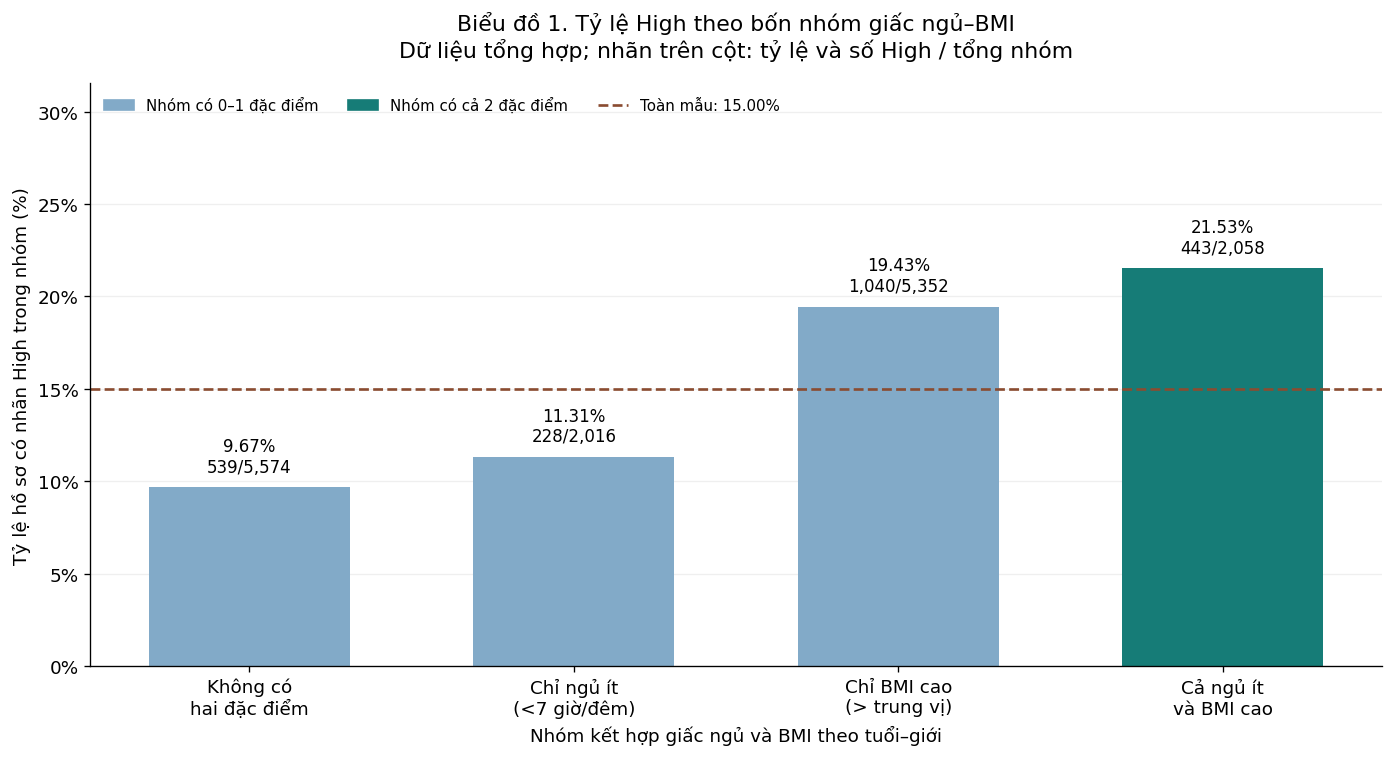

In [7]:
fig, ax = plt.subplots(figsize=(11.5, 6.2), layout='constrained')
x = np.arange(len(group_order))
colors = ['#82AAC8', '#82AAC8', '#82AAC8', '#167C77']
bars = ax.bar(x, summary.high_pct, color=colors, width=0.62)
baseline = ax.axhline(overall_pct, color='#8A4C31', linestyle='--', linewidth=1.6,
                     label=f'Toàn mẫu: {overall_pct:.2f}%')
for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.annotate(
        f'{row.high_pct:.2f}%\n{int(row.high_n):,}/{int(row.n):,}',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7), textcoords='offset points', ha='center', va='bottom', fontsize=10,
    )
ax.set_xticks(x, ['Không có\nhai đặc điểm', 'Chỉ ngủ ít\n(<7 giờ/đêm)',
                 'Chỉ BMI cao\n(> trung vị)', 'Cả ngủ ít\nvà BMI cao'])
ax.set_xlabel('Nhóm kết hợp giấc ngủ và BMI theo tuổi–giới')
ax.set_ylabel('Tỷ lệ hồ sơ có nhãn High trong nhóm (%)')
ax.set_title('Biểu đồ 1. Tỷ lệ High theo bốn nhóm giấc ngủ–BMI\n'
             'Dữ liệu tổng hợp; nhãn trên cột: tỷ lệ và số High / tổng nhóm')
ax.set_ylim(0, max(summary.high_pct.max() + 10, 30))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color='#82AAC8', label='Nhóm có 0–1 đặc điểm'),
                   Patch(color='#167C77', label='Nhóm có cả 2 đặc điểm'), baseline],
          loc='upper left', ncol=3, fontsize=9, frameon=False)
display(fig)
plt.close(fig)

### 2.2. Biểu đồ 2 — Chênh lệch theo giấc ngủ trong từng mức BMI

Hai điểm trên mỗi đường là hai nhóm BMI, không biểu diễn biến thiên theo thời gian hoặc một đường đáp ứng liên tục. Khoảng cách dọc giữa hai đường cho biết mức chênh lệch tỷ lệ High giữa nhóm ngủ <7 và ≥7 giờ/đêm ở mỗi mức BMI. Mốc BMI vẫn là trung vị tuổi–giới, không phải một ngưỡng kg/m² cố định cho toàn mẫu.

Chênh lệch của hai khoảng cách: 0.45% (mô tả).
Không suy ra ý nghĩa thống kê hoặc tương tác nhân quả từ độ dốc/độ cách của hai đường.


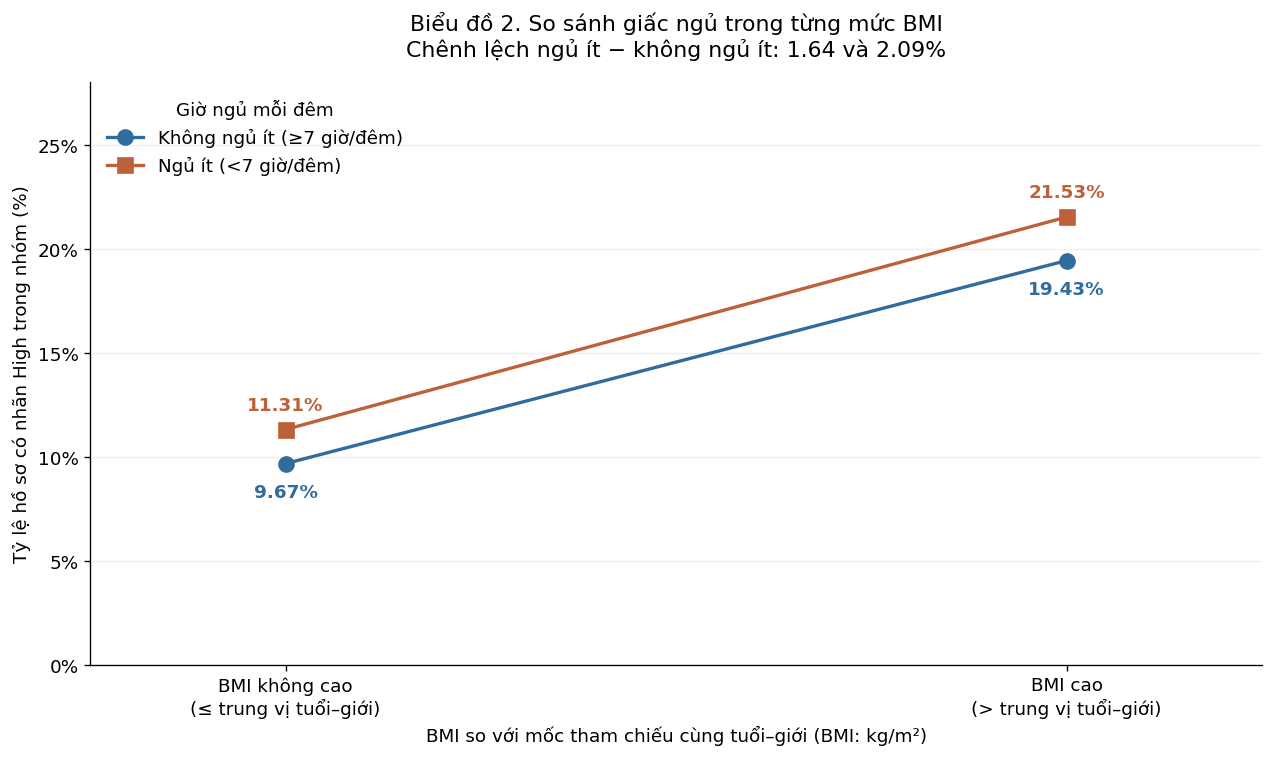

In [8]:
sleep_gap_low_bmi = summary.loc['short_only', 'high_pct'] - summary.loc['neither', 'high_pct']
sleep_gap_high_bmi = summary.loc['both', 'high_pct'] - summary.loc['bmi_only', 'high_pct']
gap_difference = sleep_gap_high_bmi - sleep_gap_low_bmi

fig, ax = plt.subplots(figsize=(10.5, 6.2), layout='constrained')
x = np.array([0, 1])
for groups, label, color, marker in [
    (['neither', 'bmi_only'], 'Không ngủ ít (≥7 giờ/đêm)', '#316C9E', 'o'),
    (['short_only', 'both'], 'Ngủ ít (<7 giờ/đêm)', '#BD613B', 's'),
]:
    values = summary.loc[groups, 'high_pct'].to_numpy()
    ax.plot(x, values, marker=marker, markersize=9, linewidth=2, color=color, label=label)
    offset = -20 if groups[0] == 'neither' else 12
    for position, value in zip(x, values):
        ax.annotate(f'{value:.2f}%', (position, value), xytext=(0, offset),
                    textcoords='offset points', ha='center', color=color, weight='bold')
ax.set_xticks(x, ['BMI không cao\n(≤ trung vị tuổi–giới)',
                 'BMI cao\n(> trung vị tuổi–giới)'])
ax.set_xlim(-0.25, 1.25)
ax.set_ylim(0, 28)
ax.set_xlabel('BMI so với mốc tham chiếu cùng tuổi–giới (BMI: kg/m²)')
ax.set_ylabel('Tỷ lệ hồ sơ có nhãn High trong nhóm (%)')
ax.set_title('Biểu đồ 2. So sánh giấc ngủ trong từng mức BMI\n'
             f'Chênh lệch ngủ ít − không ngủ ít: {sleep_gap_low_bmi:.2f} và '
             f'{sleep_gap_high_bmi:.2f}%')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title='Giờ ngủ mỗi đêm', loc='upper left', frameon=False)
display(fig)
plt.close(fig)

print(f'Chênh lệch của hai khoảng cách: {gap_difference:.2f}% (mô tả).')
print('Không suy ra ý nghĩa thống kê hoặc tương tác nhân quả từ độ dốc/độ cách của hai đường.')

## 3. Trả lời câu hỏi bằng số liệu

Trong **15.000 hồ sơ**, có **2.250 nhãn High (15,00%)**. Kết quả bốn nhóm:

| Nhóm | Số High / tổng hồ sơ | Tỷ lệ High |
| --- | ---: | ---: |
| Không có hai đặc điểm | 539 / 5.574 | 9,67% |
| Chỉ ngủ ít | 228 / 2.016 | 11,31% |
| Chỉ BMI cao | 1.040 / 5.352 | 19,43% |
| Cả ngủ ít và BMI cao | 443 / 2.058 | **21,53%** |

**Nhóm có cả hai đặc điểm có tỷ lệ High cao nhất trong bốn nhóm**, cao hơn:

- Nhóm không có đặc điểm nào **11,86%**, tỷ số tỷ lệ **2,23 lần**.
- Nhóm chỉ ngủ ít **10,22%**, tỷ số tỷ lệ **1,90 lần**.
- Nhóm chỉ BMI cao **2,09%**, tỷ số tỷ lệ **1,11 lần**.

Tỷ lệ này là tỷ lệ nhãn High trong nhóm, không phải tỷ trọng nhóm đó trong toàn bộ 2.250 hồ sơ High. Nhóm chỉ BMI cao có nhiều hồ sơ High tuyệt đối nhất (1.040) do quy mô lớn hơn; nhóm có cả hai đặc điểm có tỷ lệ trong nhóm cao nhất.

### Ý nghĩa thực tiễn và điểm bất ngờ

Chênh lệch đi cùng **BMI tương đối** lớn hơn chênh lệch đi cùng giấc ngủ trong mẫu: ở người không ngủ ít, BMI cao đi cùng mức tăng **9,76%**; ở người ngủ ít, mức tăng là **10,22%**. Ngược lại, chênh lệch ngủ ít so với không ngủ ít chỉ là **1,64%** khi BMI không cao và **2,09%** khi BMI cao.

Điểm đáng chú ý là dù nhóm “cả hai” cao hơn nhóm không có đặc điểm nào khoảng 2,23 lần, phần chênh với nhóm **chỉ BMI cao** tương đối nhỏ. Hai đường ở biểu đồ 2 gần song song: chênh lệch của hai khoảng cách chỉ **0,45%**. Vì vậy, kết quả mô tả chưa cho thấy một sự gia tăng vượt trội riêng cho tổ hợp hai đặc điểm; cũng không chứng minh hai yếu tố không tương tác.

Với mục tiêu học tập/nghiên cứu, nên tiếp tục khảo sát mối liên hệ BMI–nhãn và kiểm tra liệu chênh lệch nhỏ theo giấc ngủ còn xuất hiện trong dữ liệu thực hay sau khi kiểm soát các đặc điểm khác. Các kết quả này giúp chọn giả thuyết và thiết kế phân tích tiếp theo, chưa dùng để tư vấn giấc ngủ hay quyết định can thiệp cho cá nhân.

### Hạn chế và phạm vi diễn giải

- **Dữ liệu tổng hợp và nhãn được thiết kế:** notebook 01 ghi nhận BMI là một thành phần tạo điểm sinh nhãn, rồi nhãn được chia theo phân vị. Mối liên hệ BMI–High có thể phản ánh quy tắc mô phỏng; tỷ lệ High 15% toàn mẫu không đại diện tỷ lệ bệnh trong cộng đồng.
- **So sánh mô tả, chưa kiểm soát nhiễu:** tham chiếu BMI theo tuổi–giới không cân bằng cơ cấu tuổi/giới của bốn nhóm và không thay thế chuẩn hóa hay điều chỉnh thống kê. Tuổi, vận động, tiền sử gia đình, xét nghiệm và các yếu tố khác vẫn có thể liên quan đến nhãn. Không có dữ liệu theo dõi để xác lập thứ tự thời gian hay kết luận nhân quả.
- **Ngưỡng tương đối phụ thuộc mẫu:** các nhóm tuổi là lựa chọn phân tích; trung vị được tính trên chính mẫu, có cả hồ sơ đang được so sánh. Các nhóm `Other` chỉ có **11, 53, 75 và 14 hồ sơ** theo thứ tự nhóm tuổi nên mốc có thể kém ổn định. Gộp bảng nội bộ đáp ứng D1 về kỹ thuật, không bổ sung thông tin độc lập.
- **Làm tròn và ranh giới:** có **154 hồ sơ** BMI bằng trung vị được xếp “không cao”; **3.688 hồ sơ (24,59%)** ngủ đúng 7 giờ được xếp “không ngủ ít”. Đổi từ `<7` sang `≤7` sẽ chuyển nhiều hồ sơ; chưa đánh giá độ nhạy của kết quả với ngưỡng giờ ngủ hoặc cách chia nhóm tuổi. Nhãn không ngủ ít cũng gộp mọi số giờ ≥7, bỏ qua khác biệt bên trong nhóm.
- **Chưa đánh giá độ chắc chắn của kết quả:** các con số chỉ mô tả bộ dữ liệu hiện có. Phân tích chưa tính khoảng tin cậy hoặc thực hiện kiểm định thống kê để đánh giá kết quả có thể dao động bao nhiêu nếu lấy mẫu khác hoặc mô phỏng lại dữ liệu. Vì vậy, chênh lệch 0,45% chưa đủ để khẳng định sự khác biệt là ổn định hay chỉ do dao động ngẫu nhiên. Các hồ sơ có cờ IQR vẫn được giữ lại; chưa kiểm tra kết quả có thay đổi nhiều khi loại những hồ sơ này hay không.